In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import missingno as msno
from pathlib import Path

In [3]:
try:
    df = pd.read_excel('../../data/processed/second_one_year_mine_data_cleaned.xlsx')
    print("Data Frame Head : ")
    print(df.head())
    print("Data Frame Tail : ")
    print(df.tail())
    print("Data Frames Samples : ")
    print(df.sample())
    print("Data Frame Information : ")
    print(df.info())
    print("Data Frame Description : ")
    print(df.describe())

except FileNotFoundError:
    print("Error: The CSV file not found.")
except pd.errors.EmptyDataError:
    print("Error: The CSV file is empty.")
except pd.errors.ParserError:
    print("Error: The CSV file is malformed.")
except Exception as e:
    print(f"Unexpected error occurred: {e}")

Data Frame Head : 
        Date  PM10  PM2.5  Temperature  Relative_humidity  RF-CUMULATIVE  \
0 2025-03-04  70.8   24.1         36.1               20.4            0.0   
1 2025-03-08  69.5   32.6         36.0               22.4            0.0   
2 2025-03-11  65.2   30.4         35.5               21.8            0.0   
3 2025-03-15  76.8   26.5         34.8               38.5            0.0   
4 2025-03-18  58.4   20.4         35.1               31.4            0.0   

   Wind_speed  Road_width  \
0         8.0           7   
1         8.0           7   
2         8.0           7   
3         6.0           7   
4         7.0           7   

   Distance between the dust generation/source point and the haul road monitoring station  \
0                                                 20                                        
1                                                 20                                        
2                                                 20                  

In [4]:
print("="*80)
print("DATASET SHAPE")
print(df.shape)
print("="*80)


print("="*80)
print("FIRST FIVE ROWS")
print(df.head())
print("="*80)

print("="*80)
print("LAST FIVE ROWS")
print(df.tail())
print("="*80)


print("="*80)
print("RANDOM SAMPLE")
df.sample(5, random_state=42)
print("="*80)


print("="*80)
print("STATISTICAL SUMMARY")
print(df.describe().T)
print("="*80)


DATASET SHAPE
(576, 15)
FIRST FIVE ROWS
        Date  PM10  PM2.5  Temperature  Relative_humidity  RF-CUMULATIVE  \
0 2025-03-04  70.8   24.1         36.1               20.4            0.0   
1 2025-03-08  69.5   32.6         36.0               22.4            0.0   
2 2025-03-11  65.2   30.4         35.5               21.8            0.0   
3 2025-03-15  76.8   26.5         34.8               38.5            0.0   
4 2025-03-18  58.4   20.4         35.1               31.4            0.0   

   Wind_speed  Road_width  \
0         8.0           7   
1         8.0           7   
2         8.0           7   
3         6.0           7   
4         7.0           7   

   Distance between the dust generation/source point and the haul road monitoring station  \
0                                                 20                                        
1                                                 20                                        
2                                                

In [5]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns

print(numerical_features)

Index(['PM10', 'PM2.5', 'Temperature', 'Relative_humidity', 'RF-CUMULATIVE',
       'Wind_speed', 'Road_width',
       'Distance between the dust generation/source point and the haul road monitoring station',
       'Production_ROM', 'Production_OB', 'Production_ROM+OB',
       'Vehicle capacity'],
      dtype='object')


In [6]:
categorical_features = df.select_dtypes(include='object').columns

print(categorical_features)

Index(['LOCATION', 'SEASON'], dtype='object')


In [7]:
for column in categorical_features:
    print(f"\n{column}")
    print("-"*30)
    print(df[column].unique())


LOCATION
------------------------------
['Near Office' 'Working Area' 'Weigh Bridge' 'BZ1' 'BZ2' 'BZ3']

SEASON
------------------------------
['Summer' 'Rainy' 'Post Monsoon' 'Winter']


In [8]:
for column in categorical_features:
    print(f"\n{column}")
    print(df[column].value_counts())


LOCATION
LOCATION
Near Office     96
Working Area    96
Weigh Bridge    96
BZ1             96
BZ2             96
BZ3             96
Name: count, dtype: int64

SEASON
SEASON
Summer          144
Rainy           144
Post Monsoon    144
Winter          144
Name: count, dtype: int64


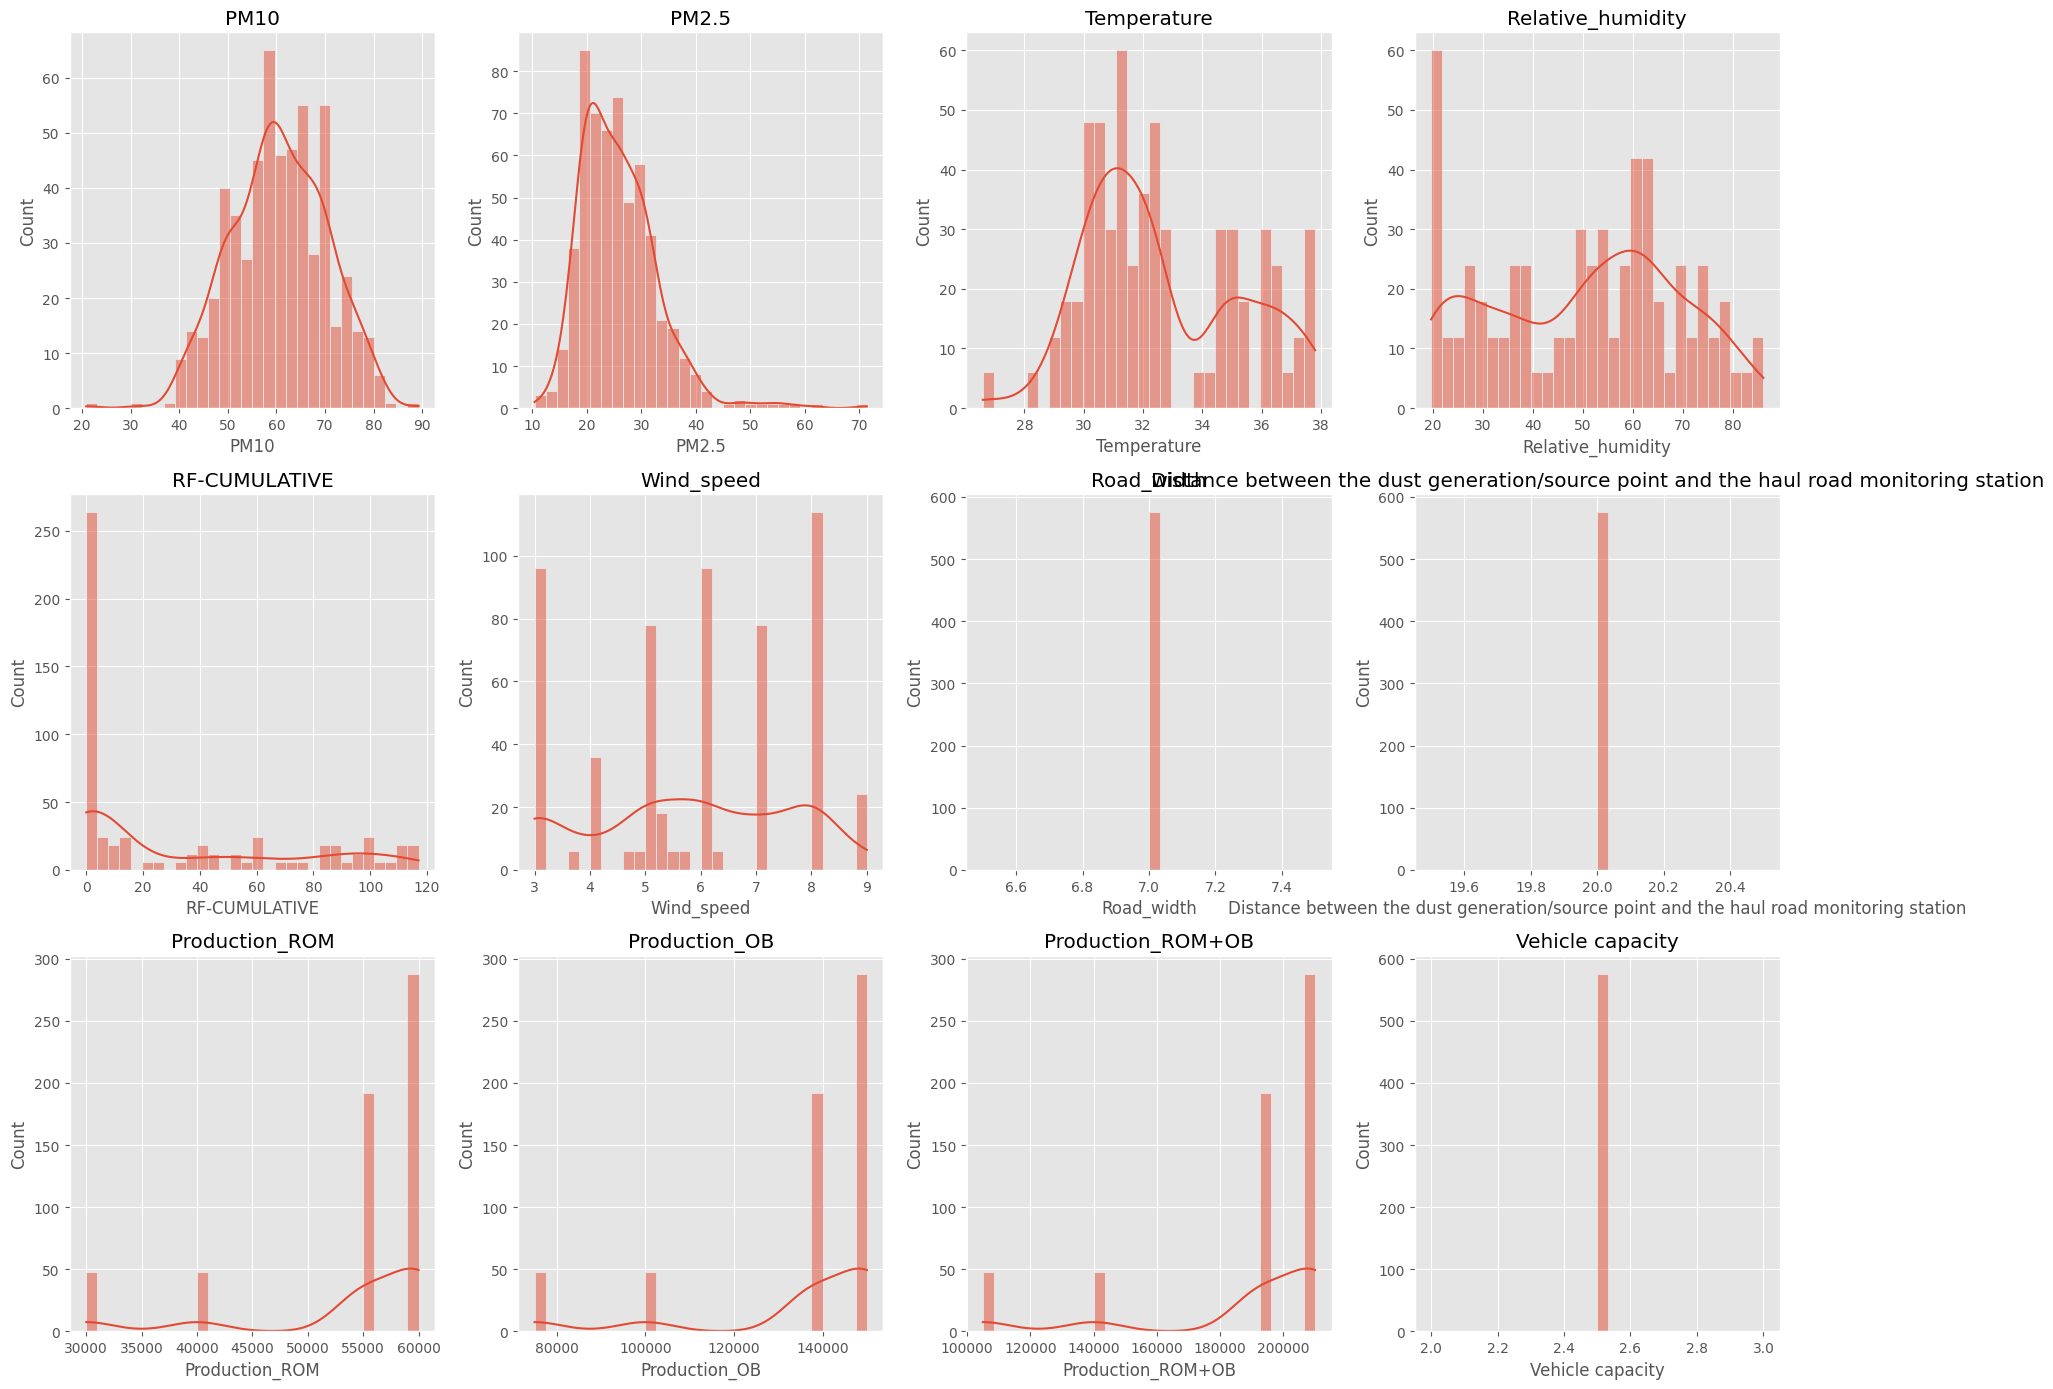

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

fig, axes = plt.subplots(3, 4, figsize=(18, 14))

axes = axes.flatten()

for i, column in enumerate(numerical_features):
    
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(column)

plt.tight_layout()

plt.show()

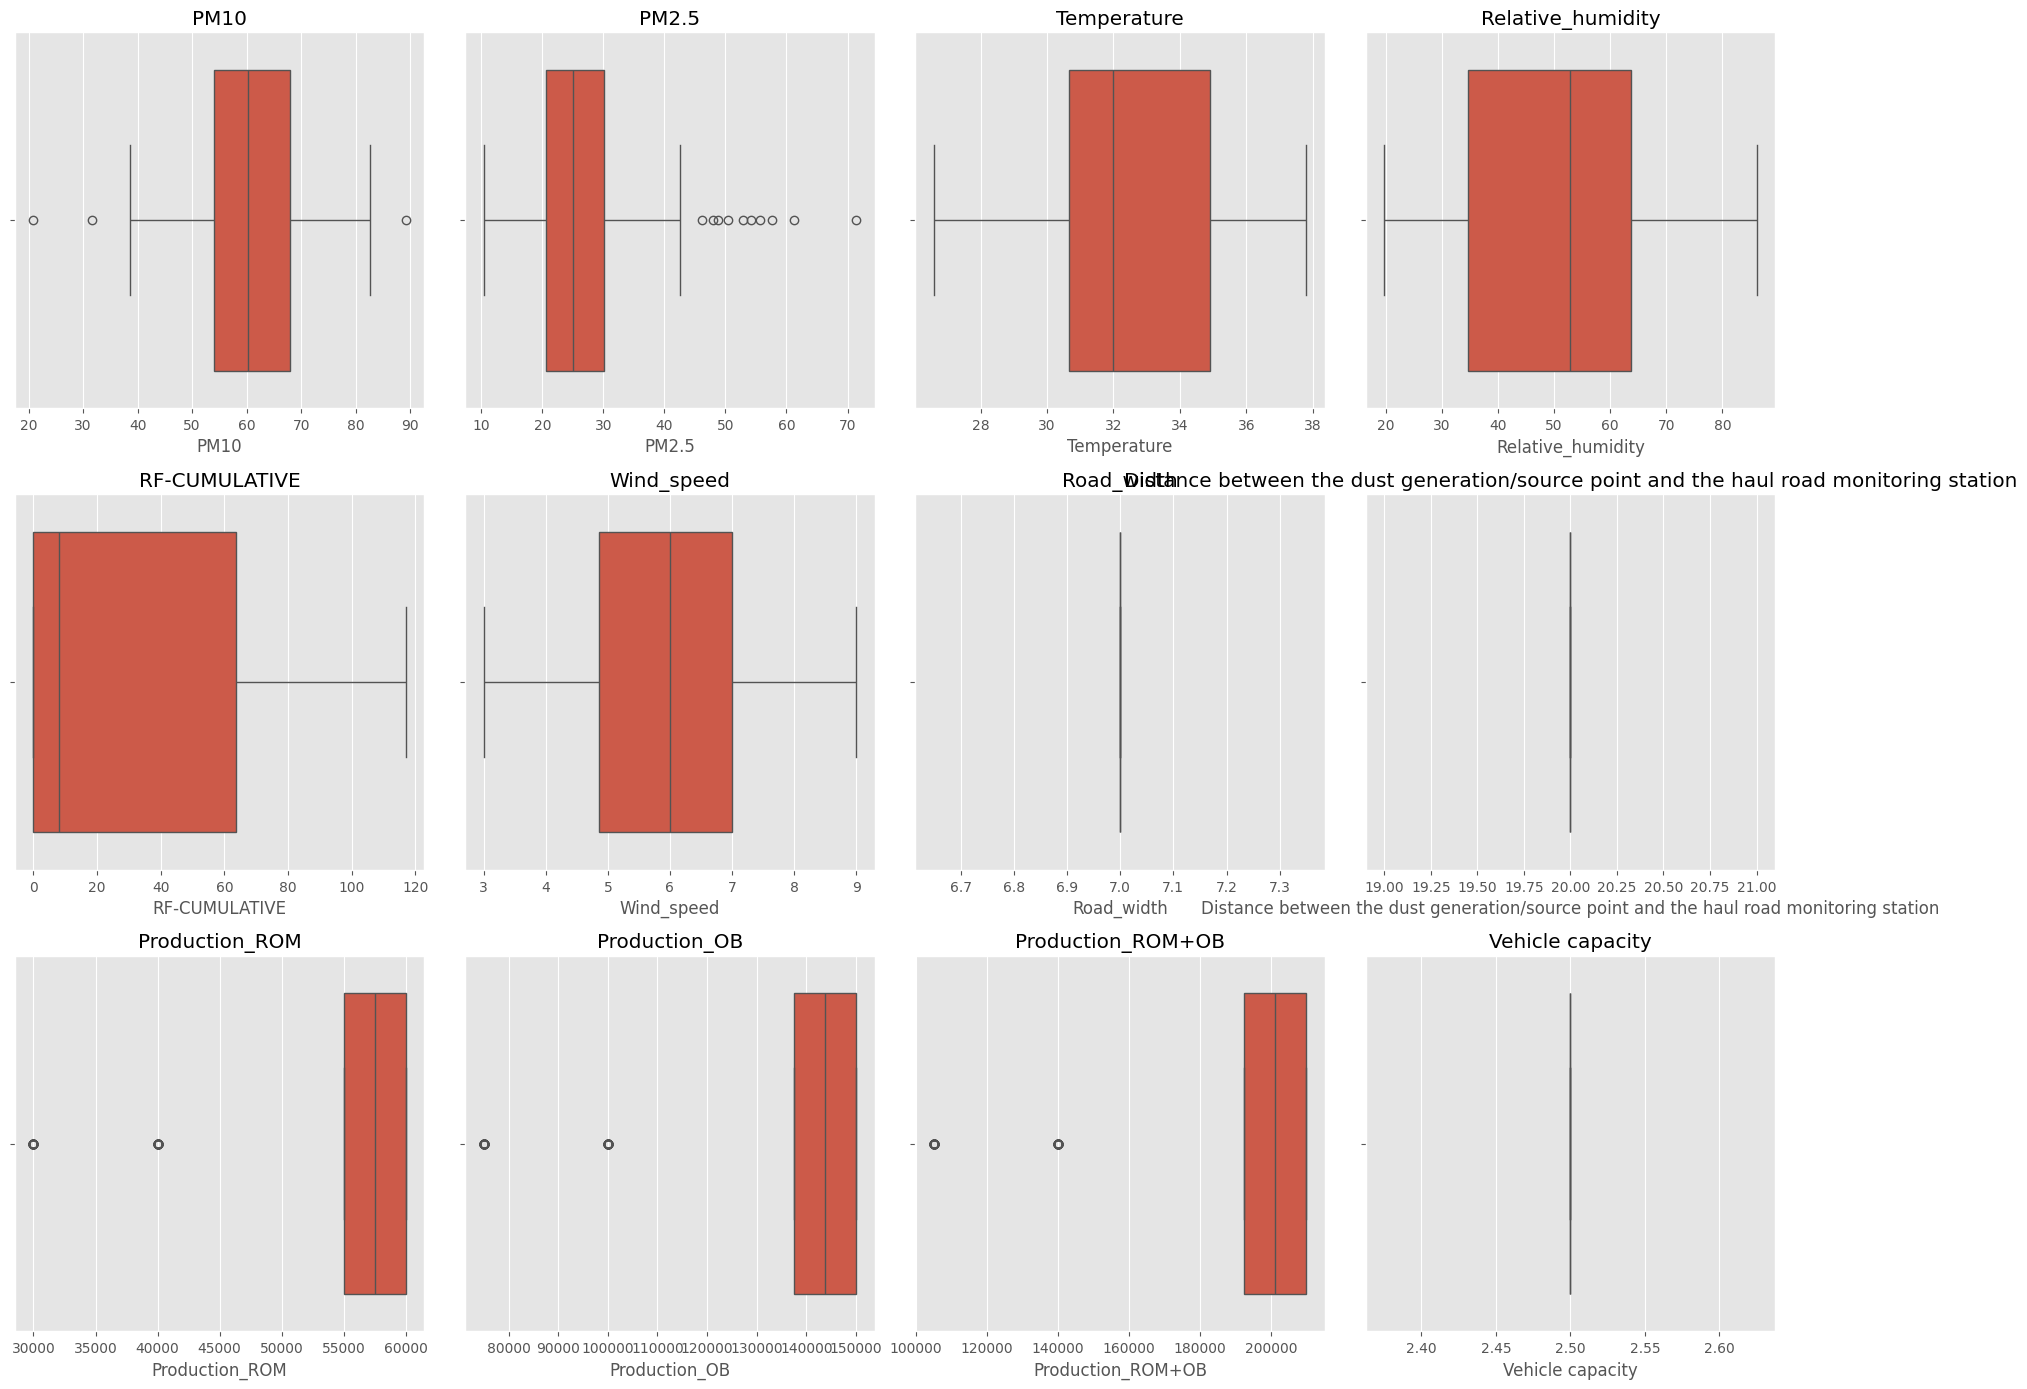

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(18, 14))

axes = axes.flatten()

for i, column in enumerate(numerical_features):

    sns.boxplot(
        x=df[column],
        ax=axes[i]
    )

    axes[i].set_title(column)

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\1291323037.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


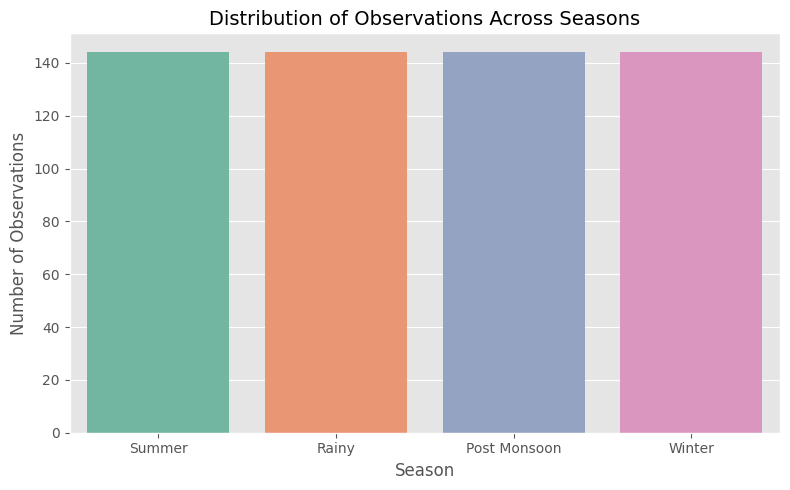

In [12]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='SEASON',
    palette='Set2',
    order=df['SEASON'].value_counts().index
)

plt.title("Distribution of Observations Across Seasons", fontsize=14)
plt.xlabel("Season")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [13]:
season_counts = df["SEASON"].value_counts()

display(season_counts)

SEASON
Summer          144
Rainy           144
Post Monsoon    144
Winter          144
Name: count, dtype: int64

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\2082458742.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


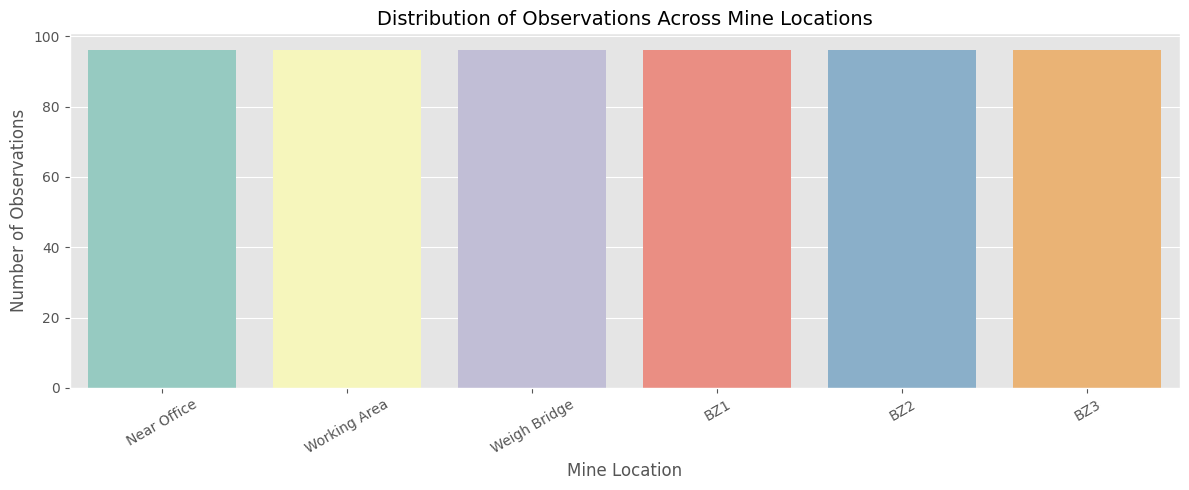

In [14]:
plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x='LOCATION',
    palette='Set3',
    order=df['LOCATION'].value_counts().index
)

plt.title("Distribution of Observations Across Mine Locations", fontsize=14)
plt.xlabel("Mine Location")
plt.ylabel("Number of Observations")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [15]:
location_counts = df["LOCATION"].value_counts()

display(location_counts)

LOCATION
Near Office     96
Working Area    96
Weigh Bridge    96
BZ1             96
BZ2             96
BZ3             96
Name: count, dtype: int64

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\3750442791.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


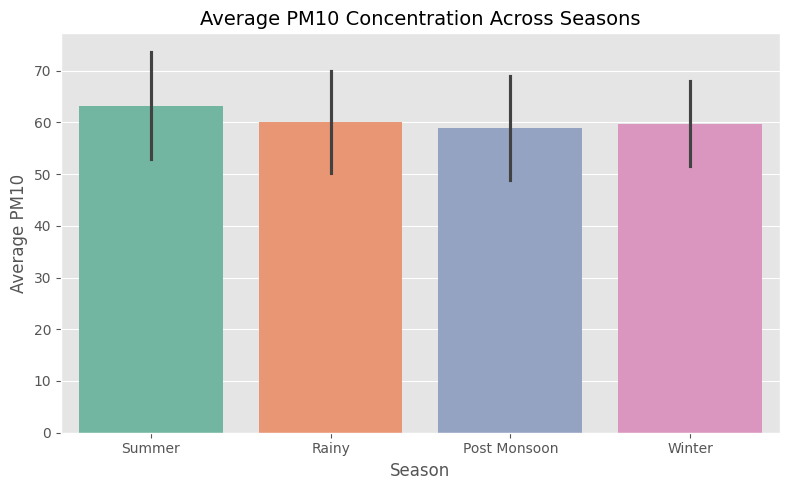

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="SEASON",
    y="PM10",
    estimator="mean",
    errorbar="sd",
    palette="Set2"
)

plt.title("Average PM10 Concentration Across Seasons", fontsize=14)
plt.xlabel("Season")
plt.ylabel("Average PM10")

plt.tight_layout()
plt.show()

In [17]:
df.iloc[190]

Date                                                                                      2024-06-24 00:00:00
PM10                                                                                                     46.6
PM2.5                                                                                                    20.7
Temperature                                                                                              31.0
Relative_humidity                                                                                        60.6
RF-CUMULATIVE                                                                                           101.9
Wind_speed                                                                                                4.0
Road_width                                                                                                  7
Distance between the dust generation/source point and the haul road monitoring station                     20
Production

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\2063253829.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


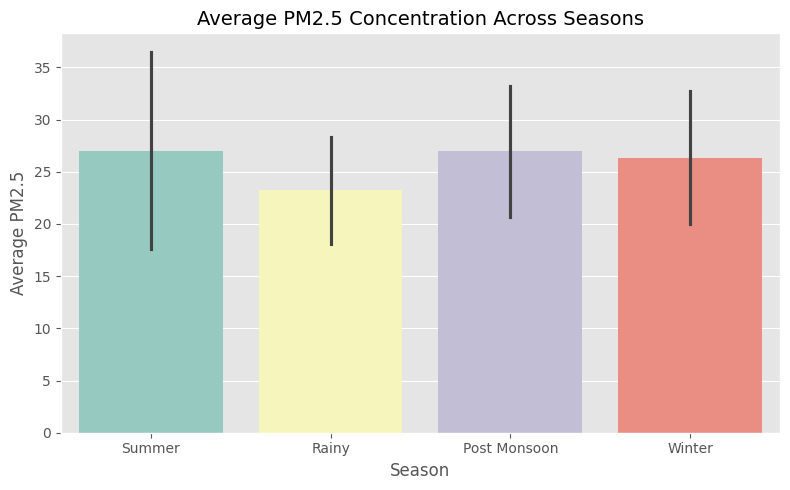

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="SEASON",
    y="PM2.5",
    estimator="mean",
    errorbar="sd",
    palette="Set3"
)

plt.title("Average PM2.5 Concentration Across Seasons", fontsize=14)
plt.xlabel("Season")
plt.ylabel("Average PM2.5")

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\2641258649.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


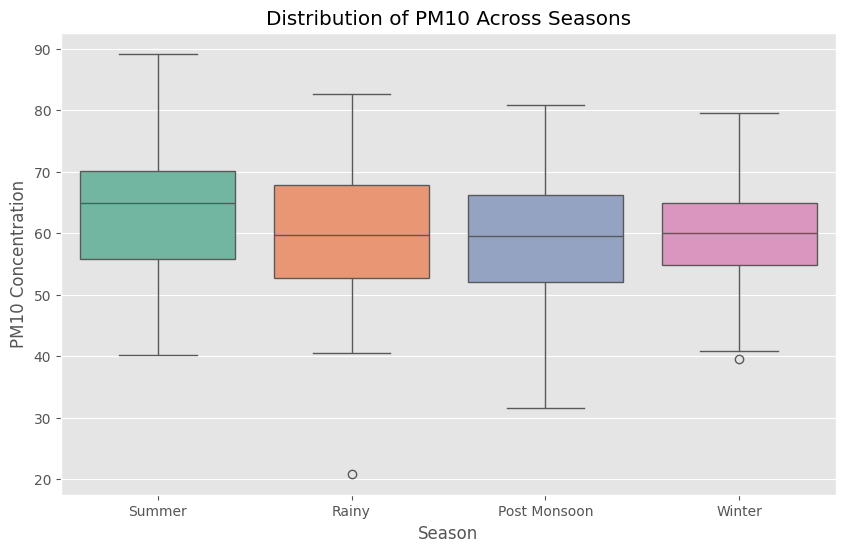

In [19]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="SEASON",
    y="PM10",
    palette="Set2"
)

plt.title("Distribution of PM10 Across Seasons")
plt.xlabel("Season")
plt.ylabel("PM10 Concentration")

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\669106898.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


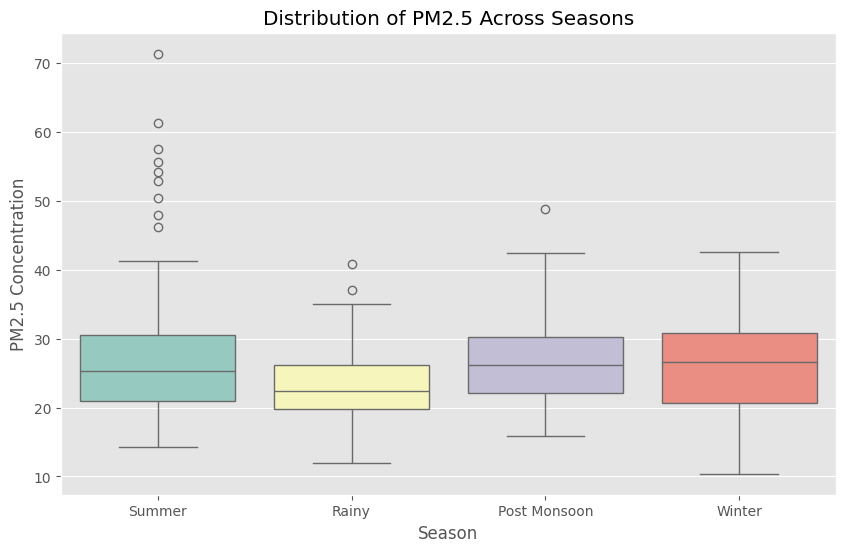

In [20]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="SEASON",
    y="PM2.5",
    palette="Set3"
)

plt.title("Distribution of PM2.5 Across Seasons")
plt.xlabel("Season")
plt.ylabel("PM2.5 Concentration")

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\4277049297.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


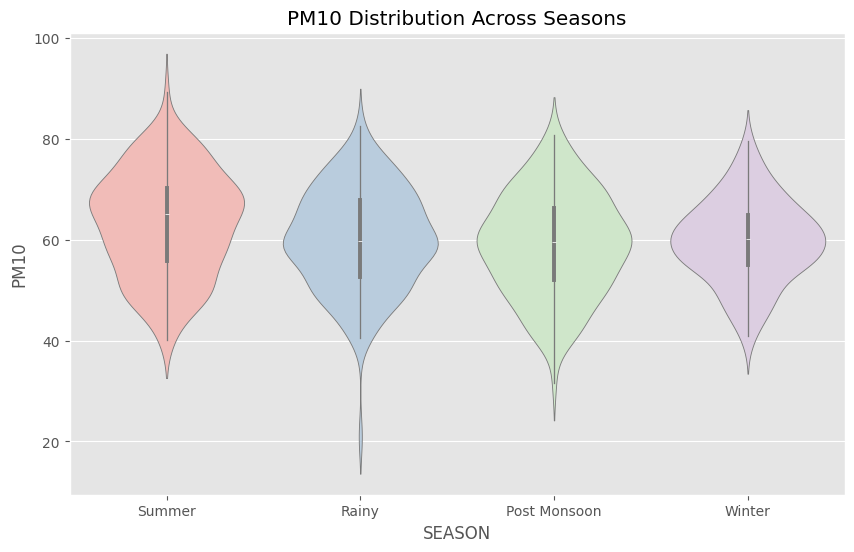

In [21]:
plt.figure(figsize=(10,6))

sns.violinplot(
    data=df,
    x="SEASON",
    y="PM10",
    palette="Pastel1"
)

plt.title("PM10 Distribution Across Seasons")

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\4067323619.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


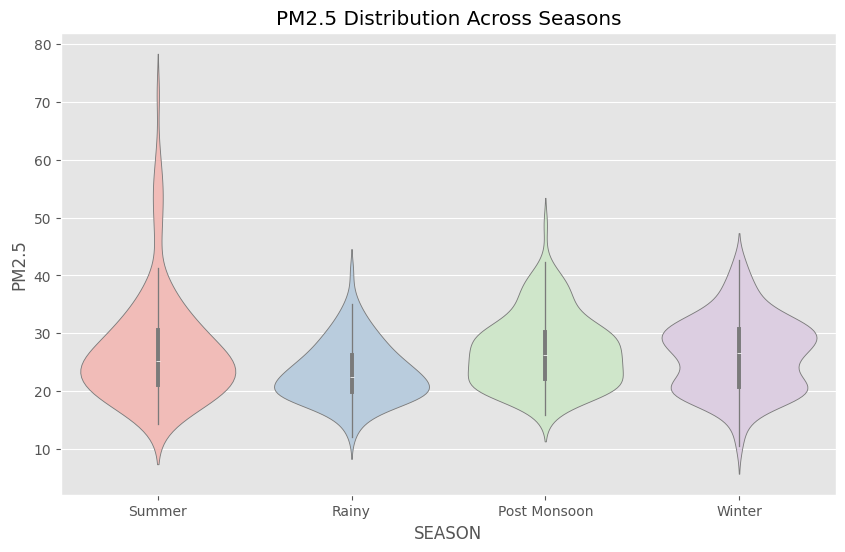

In [22]:
plt.figure(figsize=(10,6))

sns.violinplot(
    data=df,
    x="SEASON",
    y="PM2.5",
    palette="Pastel1"
)

plt.title("PM2.5 Distribution Across Seasons")

plt.show()

In [23]:
season_summary = (
    df.groupby("SEASON")[["PM10", "PM2.5"]]
      .agg(["mean", "median", "std", "min", "max"])
      .round(2)
)

display(season_summary)

PM10                            PM2.5                         
               mean median    std   min   max   mean median   std   min   max
SEASON                                                                       
Post Monsoon  58.96  59.60  10.04  31.6  80.8  26.94  26.25  6.26  15.9  48.8
Rainy         60.13  59.65   9.87  20.9  82.6  23.22  22.45  5.09  12.0  40.8
Summer        63.21  65.00  10.33  40.2  89.2  27.00  25.25  9.43  14.3  71.4
Winter        59.70  60.10   8.21  39.5  79.6  26.36  26.60  6.39  10.4  42.6

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\3447338795.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


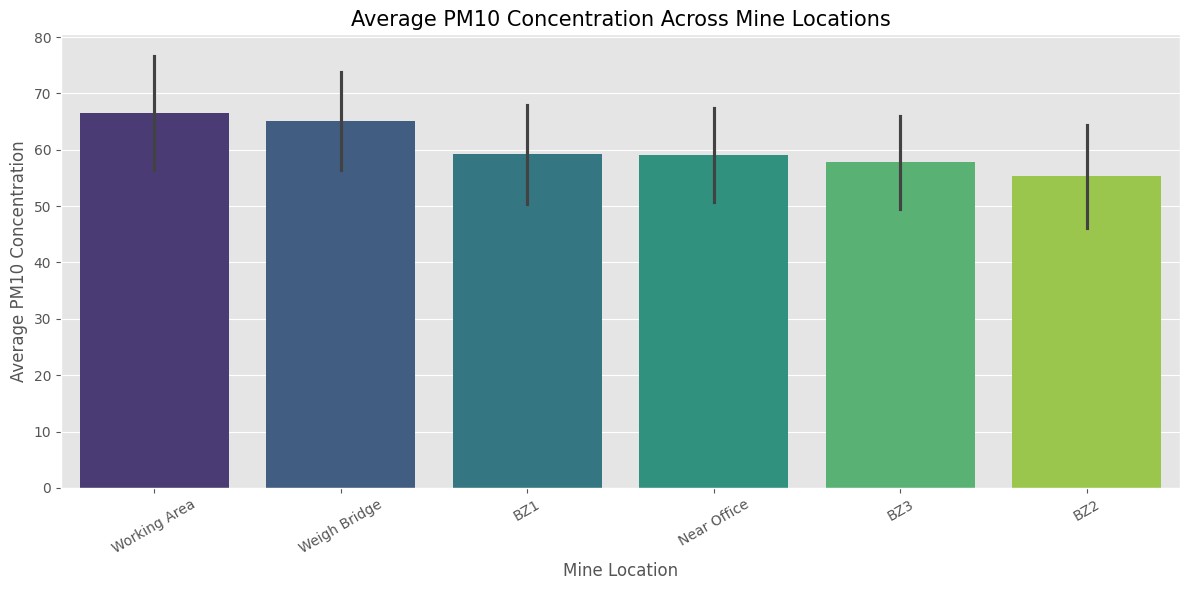

In [24]:
plt.figure(figsize=(12,6))

location_order = (
    df.groupby("LOCATION")["PM10"]
      .mean()
      .sort_values(ascending=False)
      .index
)

sns.barplot(
    data=df,
    x="LOCATION",
    y="PM10",
    order=location_order,
    estimator="mean",
    errorbar="sd",
    palette="viridis"
)

plt.title("Average PM10 Concentration Across Mine Locations", fontsize=15)
plt.xlabel("Mine Location")
plt.ylabel("Average PM10 Concentration")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\3580460547.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


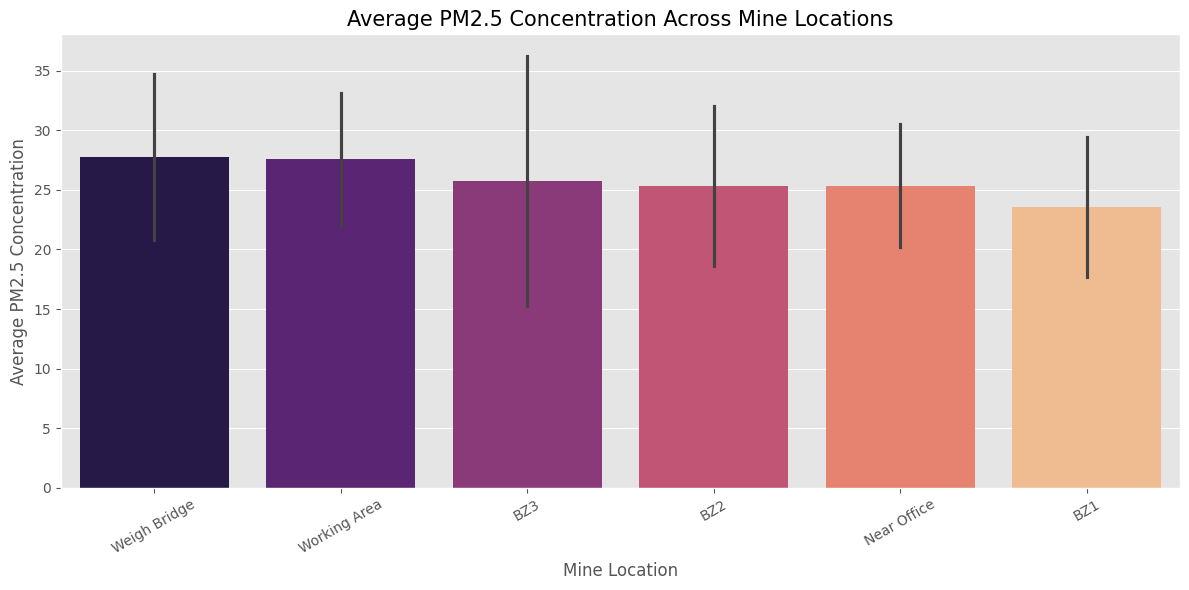

In [25]:
plt.figure(figsize=(12,6))

location_order = (
    df.groupby("LOCATION")["PM2.5"]
      .mean()
      .sort_values(ascending=False)
      .index
)

sns.barplot(
    data=df,
    x="LOCATION",
    y="PM2.5",
    order=location_order,
    estimator="mean",
    errorbar="sd",
    palette="magma"
)

plt.title("Average PM2.5 Concentration Across Mine Locations", fontsize=15)
plt.xlabel("Mine Location")
plt.ylabel("Average PM2.5 Concentration")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\3419003802.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


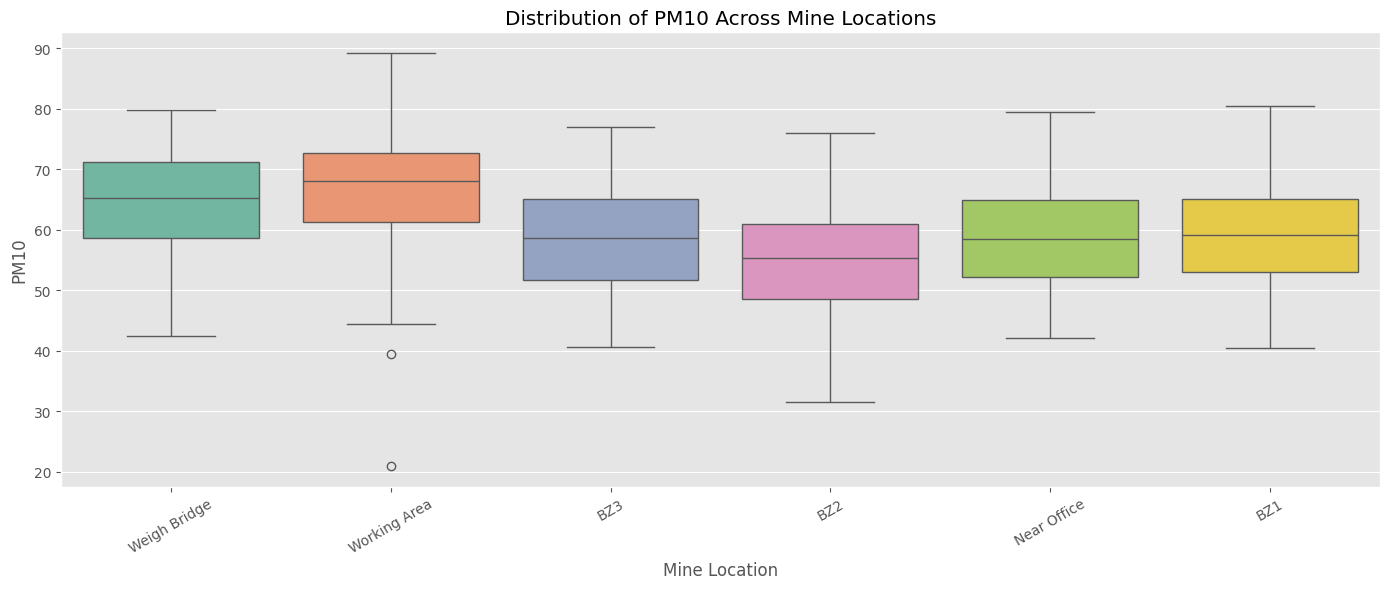

In [26]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df,
    x="LOCATION",
    y="PM10",
    order=location_order,
    palette="Set2"
)

plt.title("Distribution of PM10 Across Mine Locations")
plt.xlabel("Mine Location")
plt.ylabel("PM10")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\78075930.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


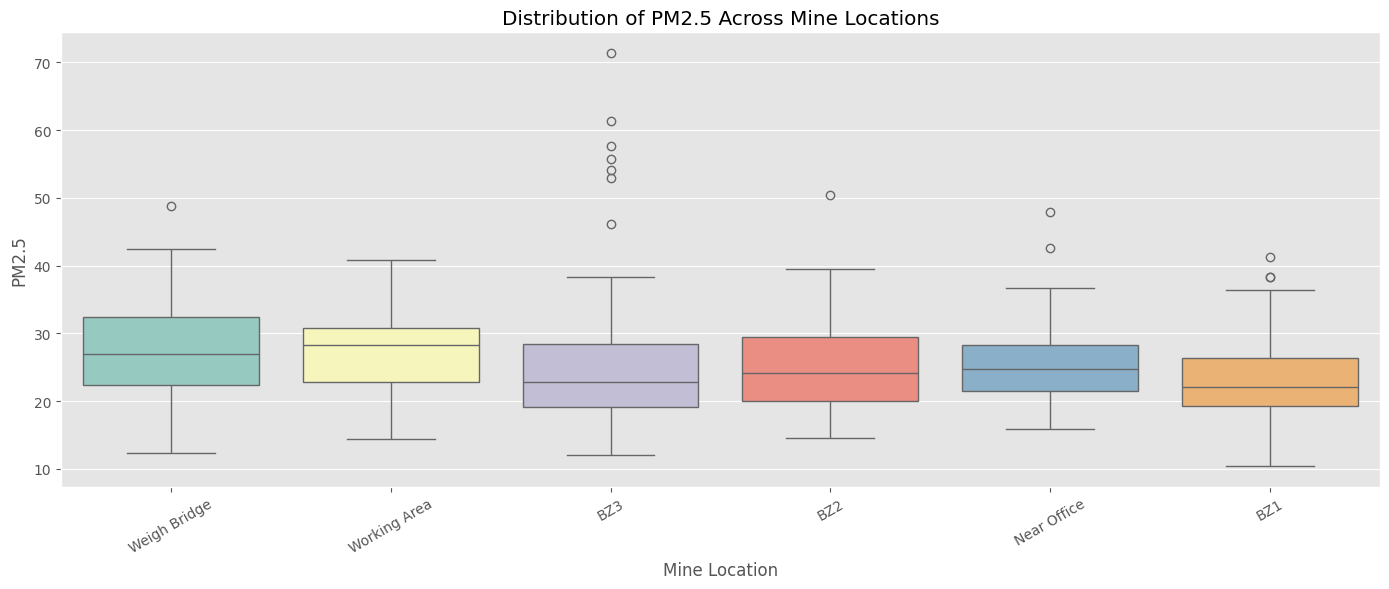

In [27]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df,
    x="LOCATION",
    y="PM2.5",
    order=location_order,
    palette="Set3"
)

plt.title("Distribution of PM2.5 Across Mine Locations")
plt.xlabel("Mine Location")
plt.ylabel("PM2.5")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\1421383249.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


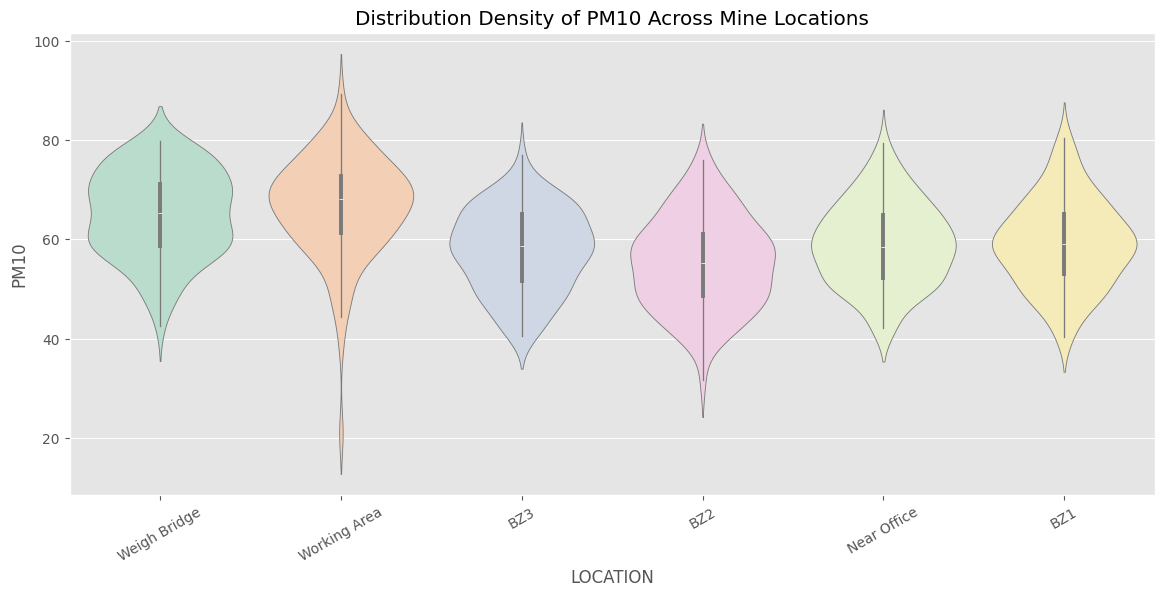

In [28]:
plt.figure(figsize=(14,6))

sns.violinplot(
    data=df,
    x="LOCATION",
    y="PM10",
    order=location_order,
    palette="Pastel2",
    legend=False
)

plt.title("Distribution Density of PM10 Across Mine Locations")

plt.xticks(rotation=30)

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_12128\2242328384.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


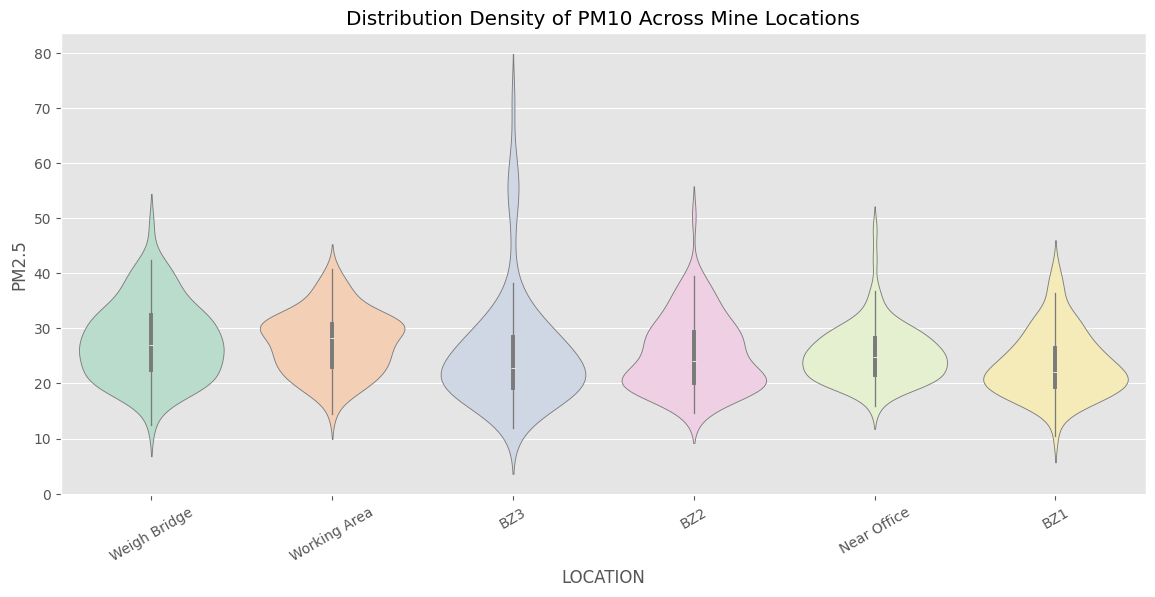

In [29]:
plt.figure(figsize=(14,6))

sns.violinplot(
    data=df,
    x="LOCATION",
    y="PM2.5",
    order=location_order,
    palette="Pastel2",
    legend=False
)

plt.title("Distribution Density of PM10 Across Mine Locations")

plt.xticks(rotation=30)

plt.show()

In [30]:
location_summary = (
    df.groupby("LOCATION")[["PM10", "PM2.5"]]
      .agg(["mean", "median", "std", "min", "max"])
      .round(2)
)

display(location_summary)

PM10                            PM2.5                          
               mean median    std   min   max   mean median    std   min   max
LOCATION                                                                      
BZ1           59.20  59.05   8.81  40.4  80.5  23.58  22.15   5.87  10.4  41.3
BZ2           55.27  55.30   9.19  31.6  75.9  25.33  24.15   6.72  14.6  50.4
BZ3           57.78  58.60   8.27  40.6  76.9  25.74  22.85  10.48  12.0  71.4
Near Office   59.08  58.40   8.35  42.1  79.4  25.33  24.80   5.16  15.9  48.0
Weigh Bridge  65.14  65.20   8.73  42.5  79.8  27.74  26.90   6.98  12.4  48.8
Working Area  66.52  68.10  10.13  20.9  89.2  27.56  28.25   5.57  14.4  40.8

In [31]:
location_ranking = (
    df.groupby("LOCATION")[["PM10", "PM2.5"]]
      .mean()
      .sort_values(by="PM10", ascending=False)
      .round(2)
)

display(location_ranking)

,PM10,PM2.5
LOCATION,,
Working Area,66.52,27.56
Weigh Bridge,65.14,27.74
BZ1,59.20,23.58
Near Office,59.08,25.33
BZ3,57.78,25.74
BZ2,55.27,25.33


In [32]:
df.columns = df.columns.str.strip()

weather_features = [
    "Temperature",
    "Relative_humidity",
    "RF-CUMULATIVE",
    "Wind_speed"
]

targets = ["PM10", "PM2.5"]

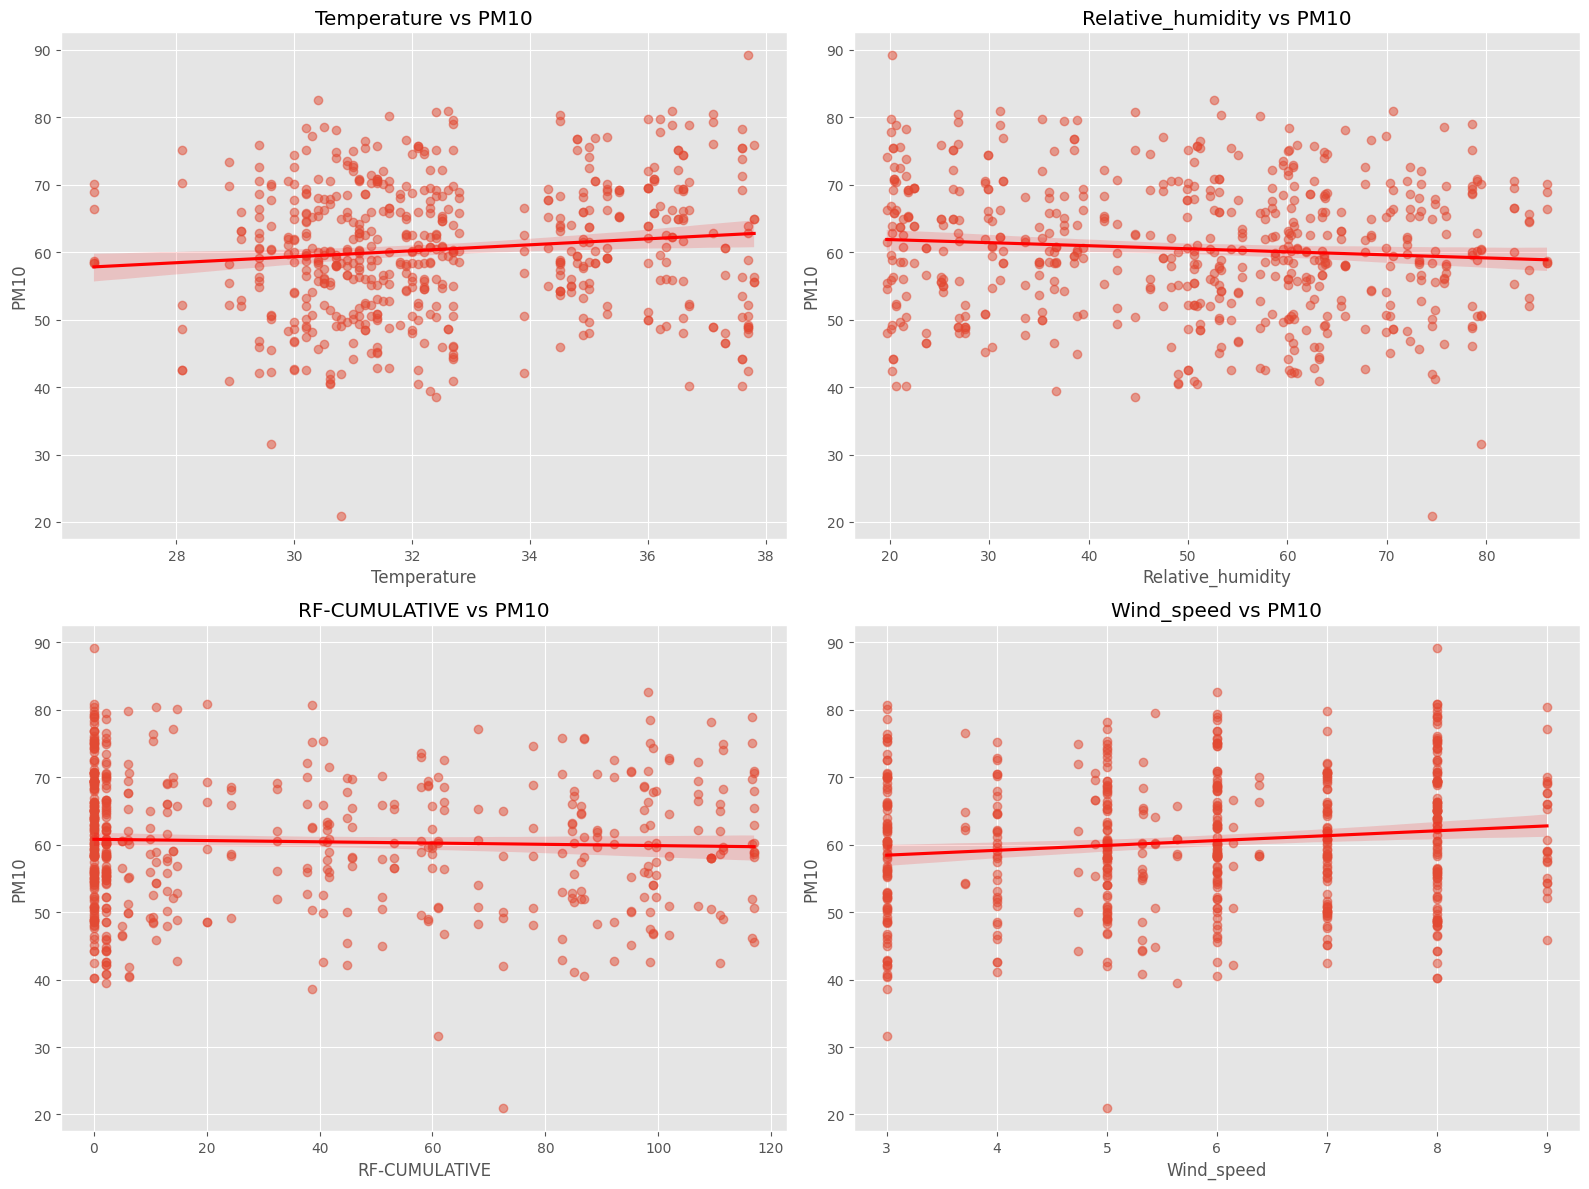

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes = axes.flatten()

for i, feature in enumerate(weather_features):

    sns.regplot(
        data=df,
        x=feature,
        y="PM10",
        scatter_kws={"alpha":0.5},
        line_kws={"color":"red"},
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs PM10")

plt.tight_layout()
plt.show()

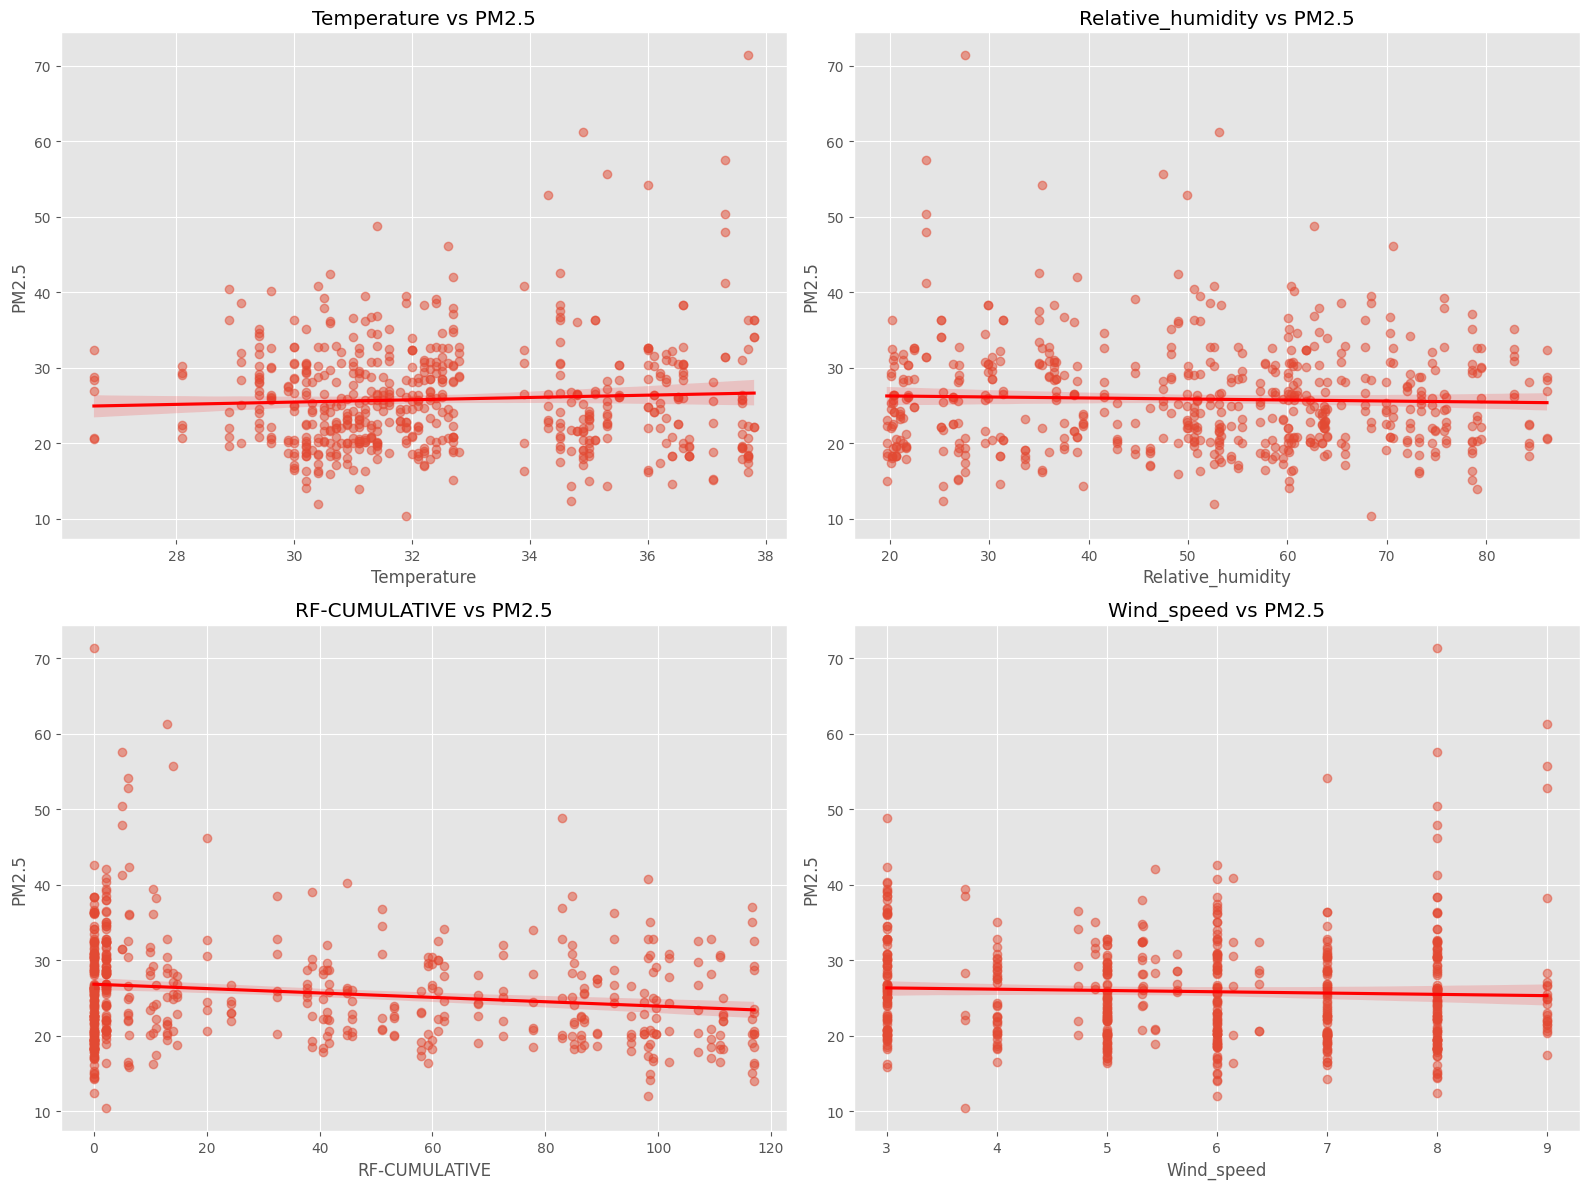

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes = axes.flatten()

for i, feature in enumerate(weather_features):

    sns.regplot(
        data=df,
        x=feature,
        y="PM2.5",
        scatter_kws={"alpha":0.5},
        line_kws={"color":"red"},
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs PM2.5")

plt.tight_layout()
plt.show()

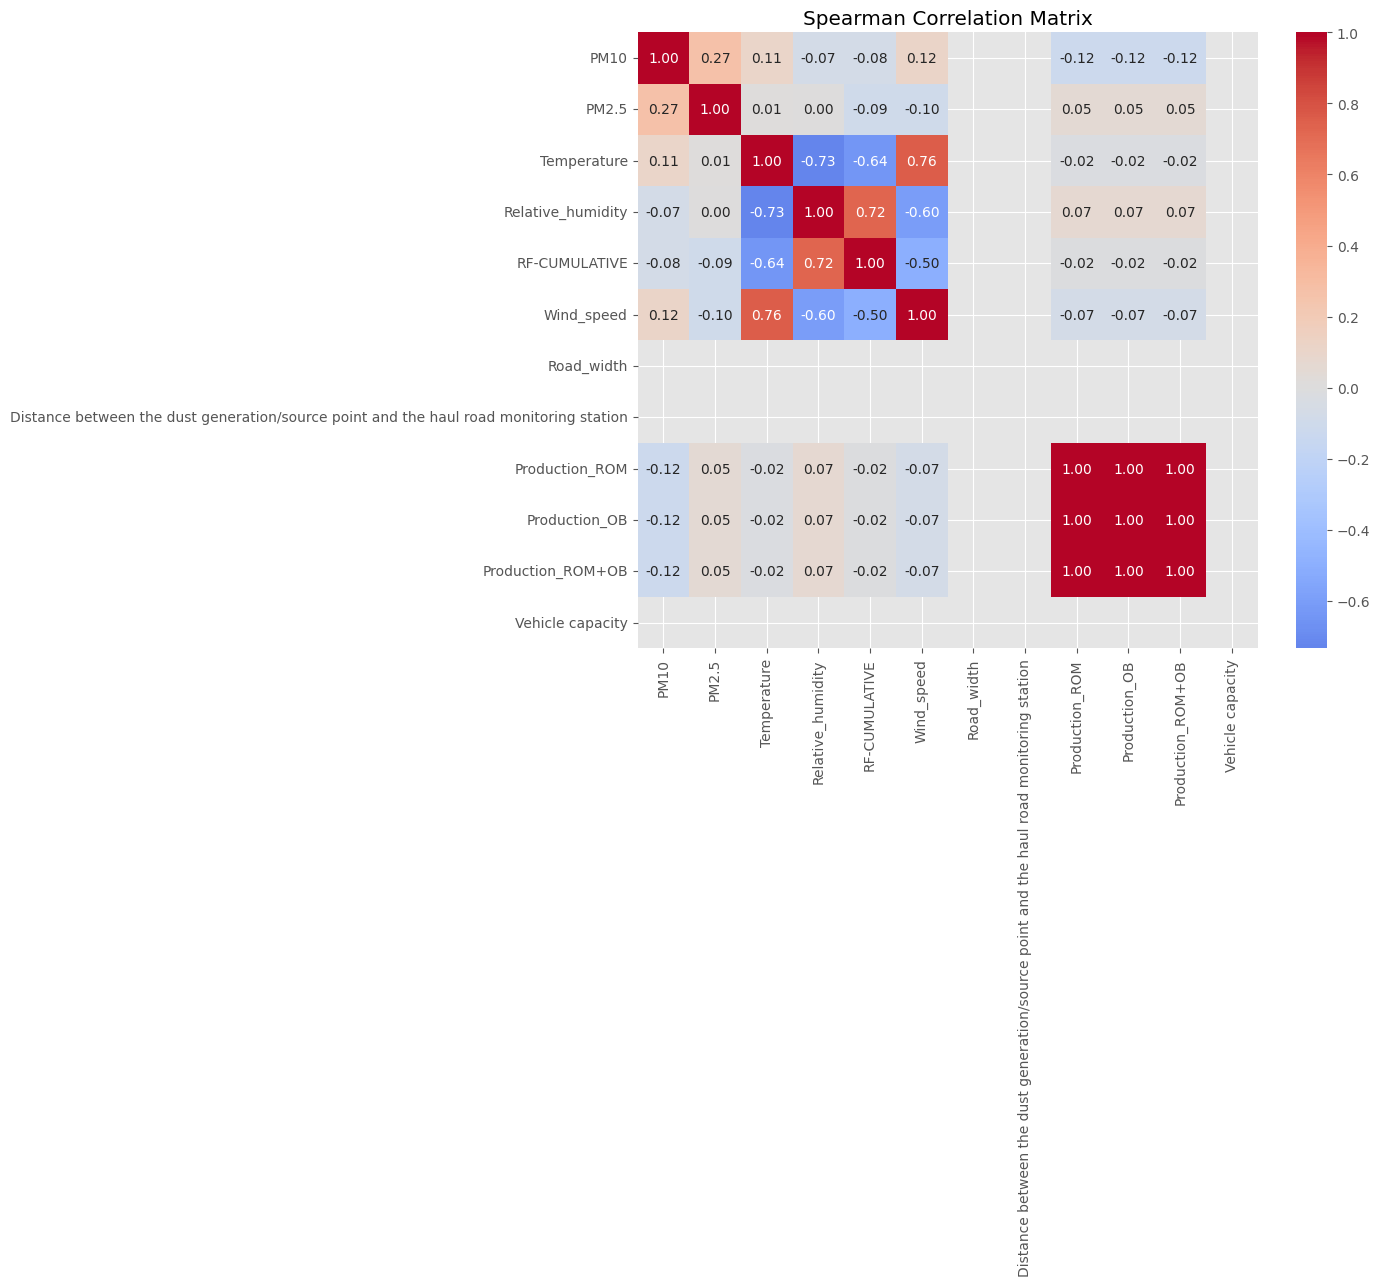

In [35]:
plt.figure(figsize=(10,8))

corr = df.corr(method="spearman", numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Spearman Correlation Matrix")

plt.show()

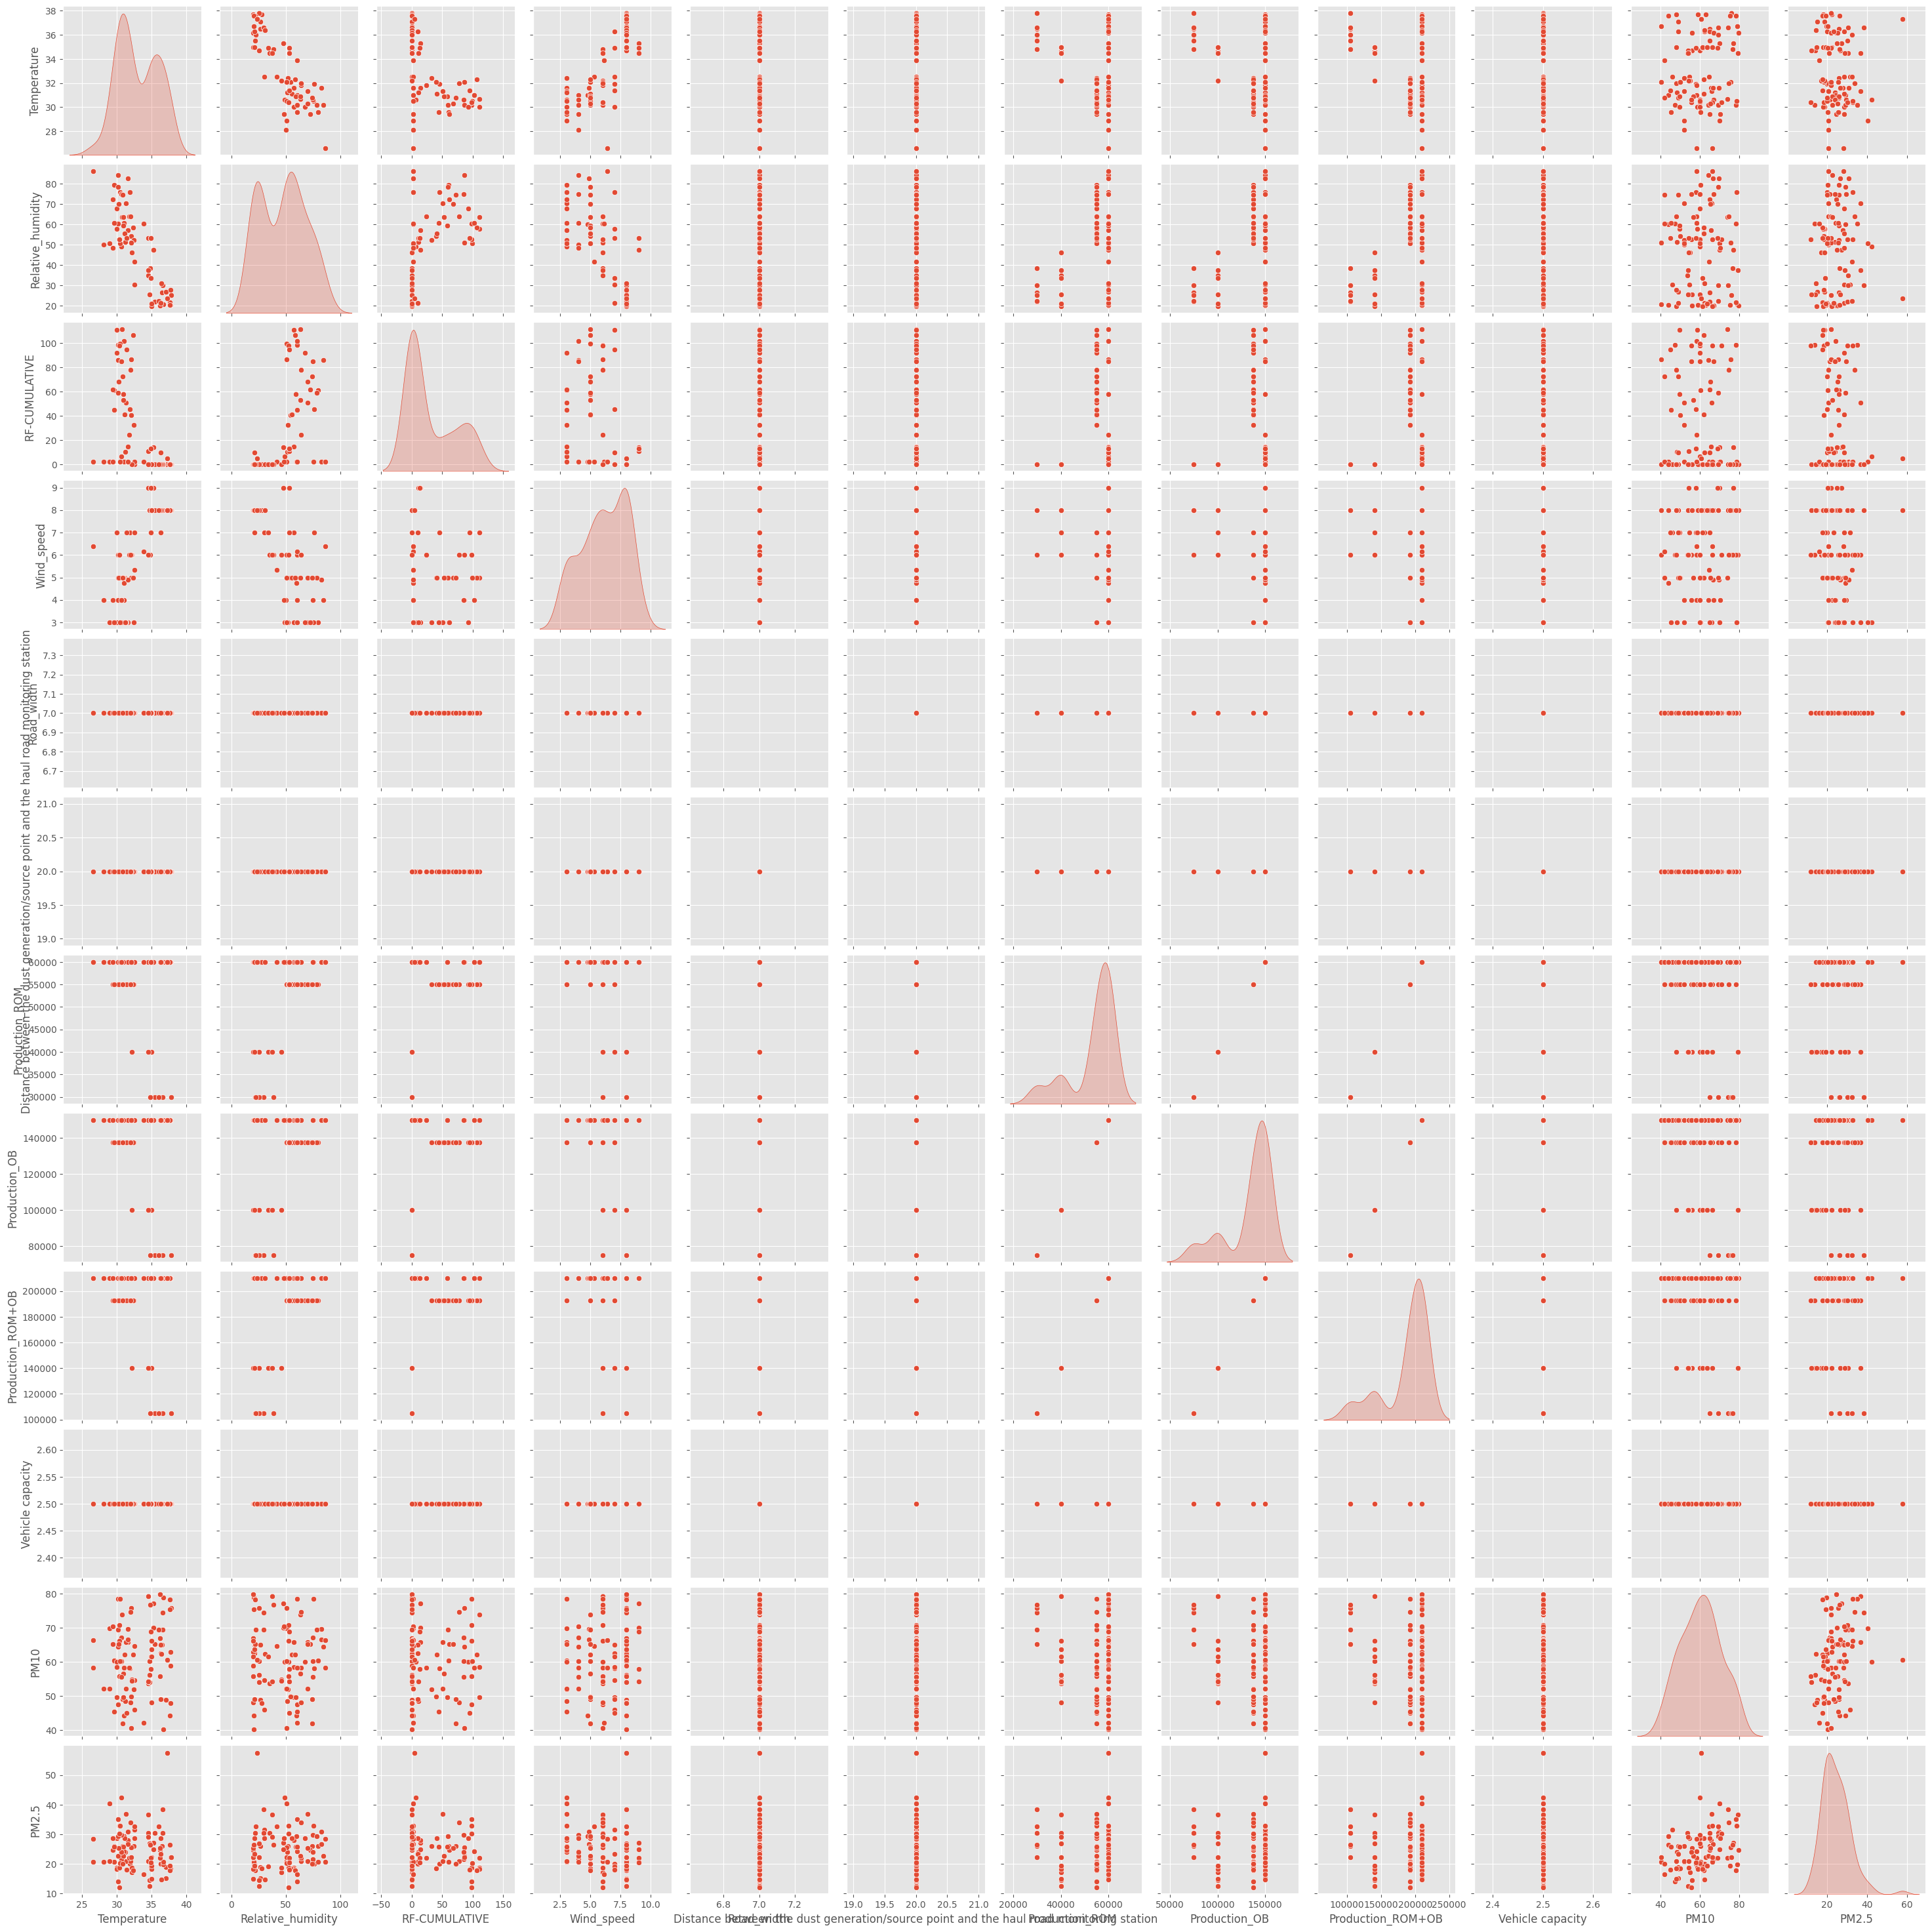

In [36]:
selected_columns = [
    "Temperature",
    "Relative_humidity",
    "RF-CUMULATIVE",
    "Wind_speed",
    "Road_width",
    "Distance between the dust generation/source point and the haul road monitoring station",
    "Production_ROM",
    "Production_OB",
    "Production_ROM+OB",
    "Vehicle capacity",
    "LOCATION",
    "SEASON",
    "PM10",
    "PM2.5"
]

sns.pairplot(
    df[selected_columns].sample(100, random_state=42),
    diag_kind="kde"
)

plt.show()

In [37]:
corr_pm10 = df[weather_features + ["PM10"]].corr()["PM10"][:-1]

corr_pm25 = df[weather_features + ["PM2.5"]].corr()["PM2.5"][:-1]

display(corr_pm10.sort_values(key=abs, ascending=False))

display(corr_pm25.sort_values(key=abs, ascending=False))

Wind_speed           0.133954
Temperature          0.117969
Relative_humidity   -0.087124
RF-CUMULATIVE       -0.038916
Name: PM10, dtype: float64

RF-CUMULATIVE       -0.164744
Temperature          0.055664
Wind_speed          -0.043367
Relative_humidity   -0.035239
Name: PM2.5, dtype: float64